# EDA — Détection de fraude sur cartes bancaires

Objectif : comprendre les données **avant** toute modélisation. Le jeu de données `creditcard.csv` (Kaggle, *Credit Card Fraud Detection*) est à placer dans `data/` (voir `data/README.md`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/creditcard.csv')
df.shape

(284807, 31)

## 1. Structure et qualité des données

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(1081)

In [9]:
df = df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**À noter :** valeurs manquantes : 0, le nombre de doublons : 1081 et après suppression 0.

## 2. Déséquilibre des classes

Class
0    283253
1       473
Name: count, dtype: int64 
 Class
0    0.99833
1    0.00167
Name: proportion, dtype: float64


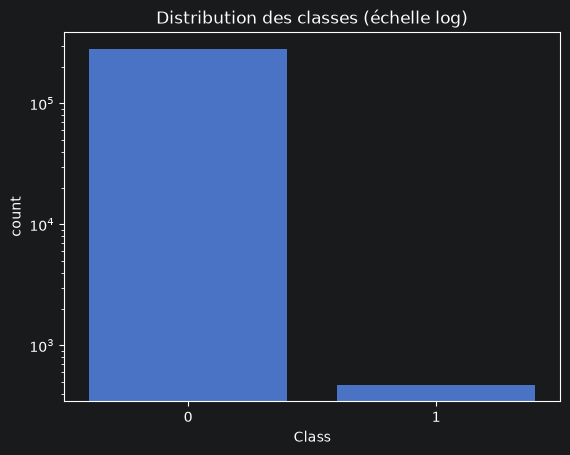

In [12]:
counts = df['Class'].value_counts()
print(counts, '\n', df['Class'].value_counts(normalize=True).round(5))
sns.countplot(x='Class', data=df); plt.yscale('log'); plt.title('Distribution des classes (échelle log)');

**À noter :** part de fraudes. Pourquoi l'accuracy est trompeuse (un modèle qui répond toujours « légitime » aurait ~99,8 % d'accuracy) ?

## 3. Montant et heure

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


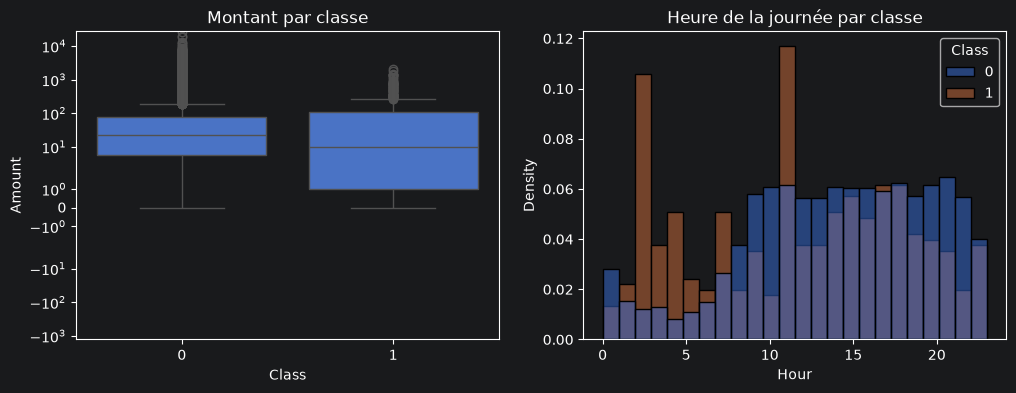

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='Class', y='Amount', data=df, ax=ax[0]); ax[0].set_yscale('symlog'); ax[0].set_title('Montant par classe')
df['Hour'] = (df['Time'] // 3600) % 24
sns.histplot(data=df, x='Hour', hue='Class', stat='density', common_norm=False, bins=24, ax=ax[1]); ax[1].set_title('Heure de la journée par classe')
df.groupby('Class')['Amount'].describe()

Montant : la médiane des fraudes est plus basse (9,82 € contre 22 €), avec beaucoup de petits montants, mais leur moyenne est plus haute (124 € contre 88 €) à cause de quelques gros montants. Les deux boxplots se chevauchent : le montant seul ne permet pas de repérer une fraude.
Heure : les fraudes se concentrent sur certains créneaux, alors que les transactions légitimes suivent un rythme jour/nuit.

## 4. Variables V1–V28 (PCA)

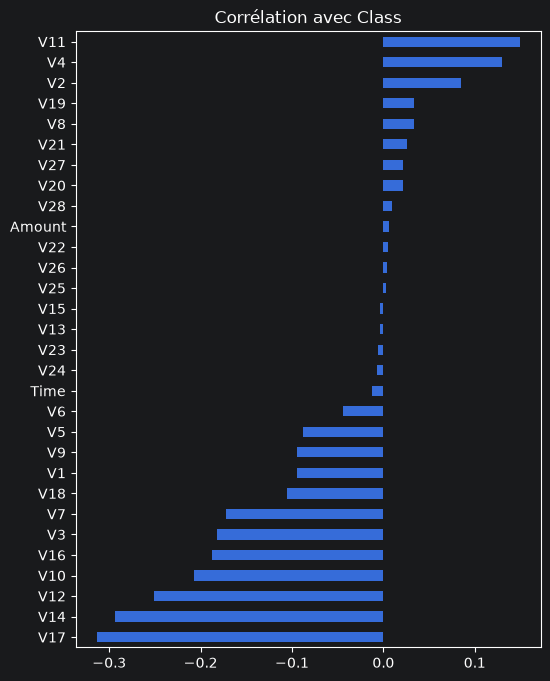

In [14]:
corr = df.drop(columns=['Hour']).corr()['Class'].drop('Class').sort_values()
corr.plot(kind='barh', figsize=(6, 8), title='Corrélation avec Class');

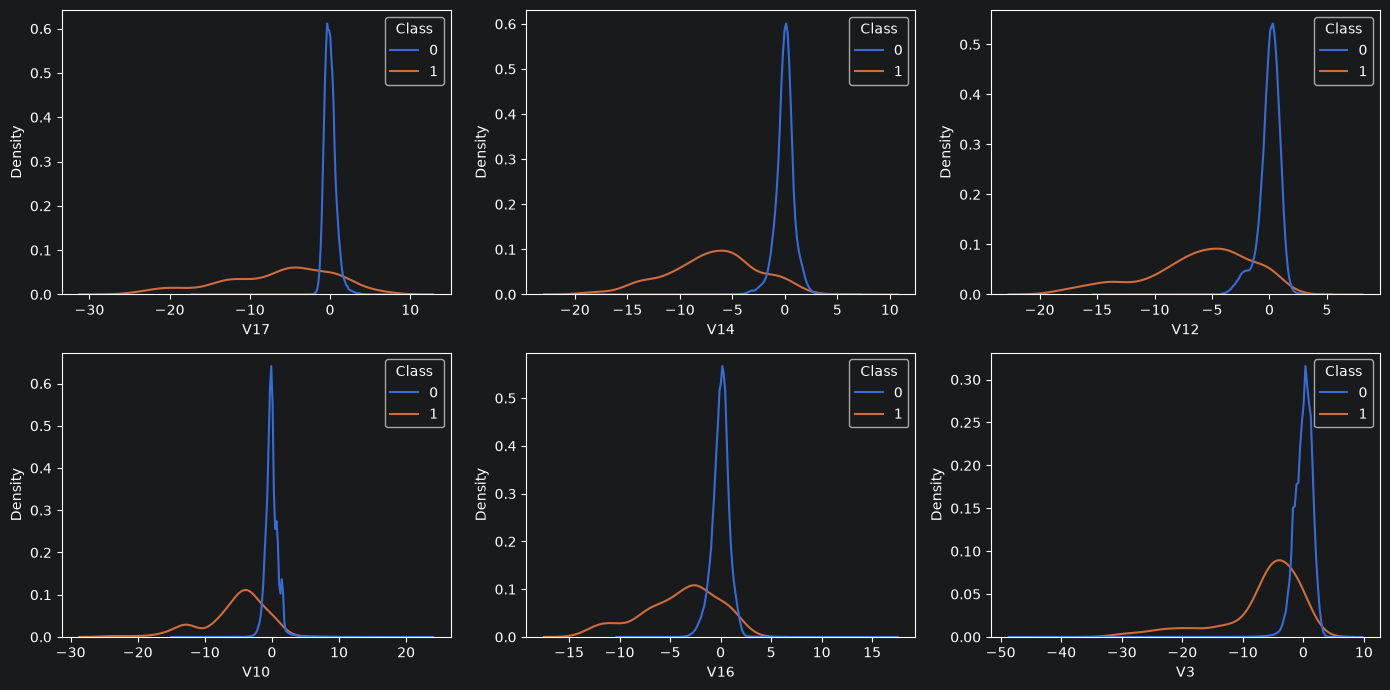

In [15]:
top = corr.abs().sort_values(ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(axes.ravel(), top):
    sns.kdeplot(data=df, x=c, hue='Class', common_norm=False, ax=a)
plt.tight_layout()

**Corrélations** : V17 (que ton graphique coupe en bas), V14, V12, V10, V16 et V3 sont les plus liées à la fraude dans le sens négatif ; V11, V4 et V2 dans le sens positif. Time et Amount sont presque à zéro. La corrélation ne mesure que le lien linéaire, donc ce n'est qu'un premier indice.

**Distributions** : chez les transactions légitimes, les V se concentrent autour de 0. Chez les fraudes, elles sont décalées vers le négatif et très étalées, avec parfois plusieurs bosses (V12 par exemple). Cela suggère plusieurs types de fraude, ce qui favorise les modèles à arbres comme XGBoost par rapport à la régression logistique. La partie des fraudes qui chevauche la zone centrale sera difficile à détecter : c'est là que se jouera le compromis Recall/Precision.

## 5. Conclusions pour la modélisation

- [ ] Doublons supprimés avant le split
- [ ] Split stratifié isolé dès le départ
- [ ] Métriques retenues : PR-AUC, Recall/Precision au seuil choisi, coût métier
- [ ] Stratégies comparées : pondération des classes vs SMOTE (dans le pipeline)

*(à compléter avec tes observations)*